In [1]:
# Day 8: Metrics and Imbalanced Data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

from sklearn.linear_model import LogisticRegression

In [2]:
# Generate an imbalanced classification dataset

X, y = make_classification(
    n_samples=1000,
    n_features=5,
    n_informative=3,
    n_redundant=0,
    n_classes=2,
    weights=[0.90, 0.10],
    random_state=42
)

# Convert into a DataFrame

df = pd.DataFrame(
    X,
    columns=["Feature_1", "Feature_2", "Feature_3",
             "Feature_4", "Feature_5"]
)

df["Target"] = y

# Display dataset information

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nClass Distribution:")
print(df["Target"].value_counts())

print("\nClass Distribution in Percentage:")
print(df["Target"].value_counts(normalize=True) * 100)

Dataset Shape: (1000, 6)

First 5 Records:


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Target
0,-0.529332,-0.093387,-1.526572,0.406847,-0.619699,0
1,-0.978500,-1.690672,-2.175214,-0.995289,0.493251,0
2,-2.171571,0.545787,-0.244730,-0.129407,-1.474666,0
3,-0.151299,-0.365506,1.390122,0.850257,-1.404234,0
4,-0.777371,1.146030,-2.479343,0.297014,1.518522,0



Class Distribution:
Target
0    894
1    106
Name: count, dtype: int64

Class Distribution in Percentage:
Target
0    89.4
1    10.6
Name: proportion, dtype: float64


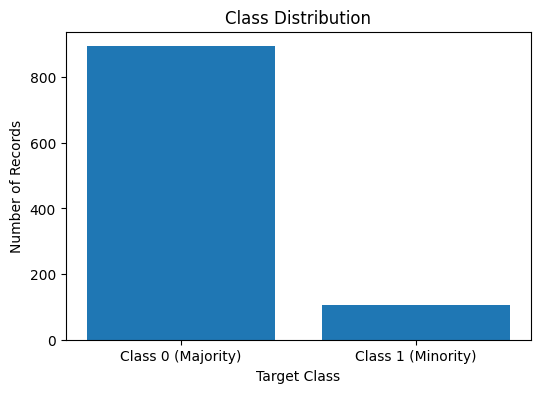

In [3]:
# Visualize class distribution

class_counts = df["Target"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ["Class 0 (Majority)", "Class 1 (Minority)"],
    class_counts.values
)

plt.title("Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")

plt.show()

In [4]:
# Separate input features and target variable

X = df.drop(columns=["Target"])
y = df["Target"]

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Features: (800, 5)
Testing Features: (200, 5)

Training Class Distribution:
Target
0    715
1     85
Name: count, dtype: int64

Testing Class Distribution:
Target
0    179
1     21
Name: count, dtype: int64


In [5]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model trained successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Model trained successfully!

First 10 Actual Values:
[0 0 0 0 0 0 1 0 0 0]

First 10 Predicted Values:
[0 0 0 0 0 0 1 0 0 0]


Confusion Matrix:
[[179   0]
 [  5  16]]


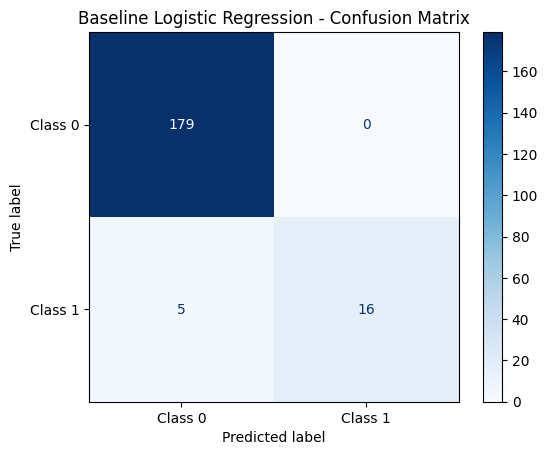

In [6]:
# Generate confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
)

display_cm.plot(cmap="Blues")
plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.show()

In [7]:
# Calculate evaluation metrics

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred, zero_division=0))

print("Recall:", recall_score(y_test, y_pred, zero_division=0))

print("F1-Score:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.975
Precision: 1.0
Recall: 0.7619047619047619
F1-Score: 0.8648648648648649

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       179
           1       1.00      0.76      0.86        21

    accuracy                           0.97       200
   macro avg       0.99      0.88      0.93       200
weighted avg       0.98      0.97      0.97       200



In [8]:
# Get predicted probabilities for Class 1

y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC

roc_auc = roc_auc_score(y_test, y_prob)

# Calculate PR-AUC (Average Precision)

pr_auc = average_precision_score(y_test, y_prob)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.9502527267890397
PR-AUC: 0.919691885523392


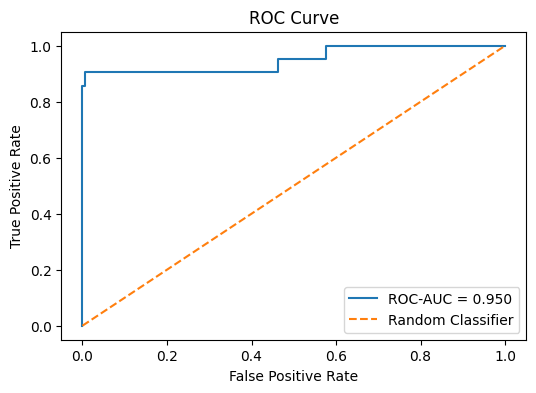

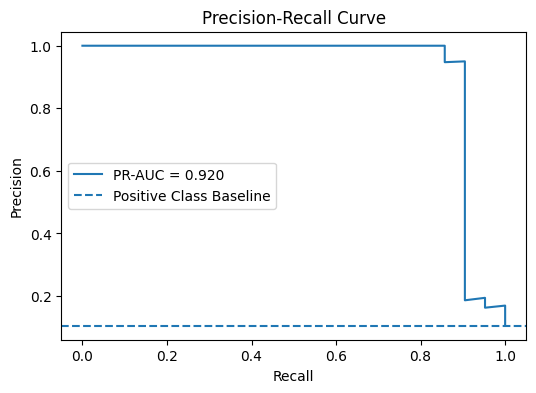

In [9]:
# Calculate ROC curve values

fpr, tpr, roc_thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


# Calculate Precision-Recall curve values

precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test, y_prob
)

plt.figure(figsize=(6, 4))
plt.plot(recall_values, precision_values, label=f"PR-AUC = {pr_auc:.3f}")

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label="Positive Class Baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

In [10]:
# Compare different classification thresholds

thresholds = [0.50, 0.40, 0.30]

threshold_results = []

for threshold in thresholds:

    y_threshold_pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, y_threshold_pred, zero_division=0),
        "Recall": recall_score(y_test, y_threshold_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_threshold_pred, zero_division=0),
        "Accuracy": accuracy_score(y_test, y_threshold_pred)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

,Threshold,Precision,Recall,F1-Score,Accuracy
0,0.5,1.0,0.762,0.865,0.975
1,0.4,1.0,0.857,0.923,0.985
2,0.3,1.0,0.857,0.923,0.985


In [11]:
class_weight="balanced"

In [12]:
# Create class-weighted Logistic Regression model

weighted_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the weighted model

weighted_model.fit(X_train, y_train)

# Generate predictions

weighted_pred = weighted_model.predict(X_test)

print("Class-weighted model trained successfully!")

Class-weighted model trained successfully!


In [13]:
# Evaluate both models

models = {
    "Baseline Logistic Regression": (model, y_pred),
    "Class-Weighted Logistic Regression": (weighted_model, weighted_pred)
}

comparison_results = []

for name, (clf, predictions) in models.items():

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(
            y_test, clf.predict_proba(X_test)[:, 1]
        ),
        "PR-AUC": average_precision_score(
            y_test, clf.predict_proba(X_test)[:, 1]
        )
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(3))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline Logistic Regression,0.975,1.000,0.762,0.865,0.950,0.920
1,Class-Weighted Logistic Regression,0.950,0.704,0.905,0.792,0.956,0.921


In [14]:
# Save model comparison report

comparison_df.to_csv("metrics_comparison.csv", index=False)

# Save threshold comparison report

threshold_df.to_csv("threshold_comparison.csv", index=False)

print("Metrics comparison saved successfully!")
print("Threshold comparison saved successfully!")

Metrics comparison saved successfully!
Threshold comparison saved successfully!
